# Classificação
A base utilizada neste experimento foi Predict Students' Dropout and Academic Success, disponibilizada no repositório UCI Machine Learning Repository.

Fonte: https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

In [56]:
%pip install ucimlrepo
%pip install pandas
%pip install numpy
%pip install scikit-learn
%pip install matplotlib

In [57]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

## Seleção e Compreensão da Base
Origem da base: Os dados vem de um repositório no site di UCM (https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success). Os criadores juntaram os dados com o intuito de ajudar na identificação da evasão de estudantes das universidades.

Problema: A evasão no ensino superior prejudica a formação dos estudantes e pode estar relacionada a fatores pessoais, acadêmicos e socioeconômicos. Então, rge a necessidade de identificar antecipadamente quais estudantes apresentam maior probabilidade de abandonar o curso, permitindo que as instituições de ensino reconheçam situações de risco e desenvolvam estratégias de apoio.

Objetivo: Desenvolver e avaliar modelos de classificação capazes de identificar estudantes com maior risco de abandono e analisar quais características dos estudantes estão mais associadas a essa situação.

A base contém diversos cursos como: agronomia, design, educação, enfermagem, jornalismo, administração, serviços sociais e tecnologias

O conjunto possui 4.424 registros e 37 colunas, sendo 36 atributos preditores e uma variável-alvo denominada Target.

A variável-alvo possui três classes:
* Dropout: estudantes que abandonaram o curso;
* Enrolled: estudantes que permanecem matriculados;
* Graduate: estudantes que concluíram o curso.

In [58]:
# Dataset predict_students_dropout_and_academic_success (estudantes)
estudantes = fetch_ucirepo(id=697) 
df_estudantes = pd.concat([estudantes.data.features, estudantes.data.targets], axis=1)

linhas_estudantes = df_estudantes.shape[0]
colunas_estudantes = df_estudantes.shape[1]

classes_estudantes = df_estudantes['Target'].unique()
contagem_classes_estudantes = df_estudantes['Target'].value_counts()
qntd_classes_estudantes = len(classes_estudantes)
porcentagem_classes_estudantes = (contagem_classes_estudantes / linhas_estudantes) * 100

distribuicao_estudantes = pd.DataFrame({
    'Quantidade': contagem_classes_estudantes,
    'Porcentagem (%)': porcentagem_classes_estudantes.round(2)
})

print("Número de linhas:", linhas_estudantes)
print("Número de colunas:", colunas_estudantes)
print("Distribuição das classes:")
print(distribuicao_estudantes)

Número de linhas: 4424
Número de colunas: 37
Distribuição das classes:
          Quantidade  Porcentagem (%)
Target                               
Graduate        2209            49.93
Dropout         1421            32.12
Enrolled         794            17.95


## Preparação de dados
Valores nulos: Os dados não apresentaram nenhum valor nulo nas 37 colunas. 

Colunas_alvo: Foi identificada a coluna Target (y_estudantes) que queremos prever e os restos das colunas que serão utilizadas como atributos (x_estudantes) 

Atributos numéricos e categóricos: Separou-se as colunas com números (numéricas)e as que possuem textos, categorias e booleanos (categóricas)

Pipeline numérico: Foi utilizado um pipeline contendo imputação pela mediana e normalização com MinMaxScaler. A imputação permite tratar possíveis valores ausentes (mesmo que essa base de dados não possua), enquanto a normalização transforma os atributos para uma escala entre 0 e 1. E

Pipeline categórico: Foi utilizado um pipeline com imputação pela categoria mais frequente e codificação One-Hot. Essa codificação transforma cada categoria em uma representação binária, permitindo que os algoritmos de classificação processem variáveis não numéricas sem atribuir uma ordem artificial entre as categorias

Combinação das pipelines: Foi utilizado o ColumnTransformer para combinar os pipelines de atributos numéricos e categóricos. Dessa forma, cada grupo de atributos recebe o tratamento adequado, e os resultados são reunidos em uma única representação que pode ser utilizada pelos algoritmos de classificação.

In [59]:
###Preparação dos dados###

valores_nulos_estudantes = df_estudantes.isnull().sum()
print("Valores nulos por coluna:", valores_nulos_estudantes)

x_estudantes = df_estudantes.drop('Target', axis=1) #atributos para utilizar nas previsões
y_estudantes = df_estudantes['Target'] #o que queremos prever

# Identificar colunas numéricas e categóricas
numericas = x_estudantes.select_dtypes(include=['number']).columns
categoricas = x_estudantes.select_dtypes(include=['object', 'category', 'bool']).columns

# Pipeline para atributos numéricos
pipeline_numerico = Pipeline([
    ('imputacao', SimpleImputer(strategy='median')),
    ('normalizacao', MinMaxScaler())
])

# Pipeline para atributos categóricos
pipeline_categorico = Pipeline([
    ('imputacao', SimpleImputer(strategy='most_frequent')),
    ('codificacao', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combinarção dos dois pipelines
preprocessador = ColumnTransformer([
    ('numerico', pipeline_numerico, numericas),
    ('categorico', pipeline_categorico, categoricas)
])

print("Classes da variável-alvo:", y_estudantes.value_counts(), "\n")



Valores nulos por coluna: Marital Status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                    

## Treinamento

Treinamento: A base foi dividida em 80% para treinamento e 20% para teste. A divisão foi realizada de forma estratificada, mantendo aproximadamente a proporção original das classes em ambos os conjuntos. O parâmetro random_state=42 foi utilizado para garantir a reprodutibilidade dos resultados. O conjunto de teste foi reservado para a avaliação final dos modelos.

KNN: Realiza a classificação com base nos vizinhos mais próximos de cada registro. Para esse algoritmo, foi avaliada a quantidade de vizinhos (n_neighbors) com os valores 5, 10 e 20.

Naive_Bayes: Utiliza o teorema de Bayes para estimar a classe de um registro, considerando a independência condicional entre os atributos. Neste experimento, foi utilizado o classificador Gaussian Naive Bayes.

Árvore de decisão: Realiza classificações por meio de regras organizadas em uma estrutura de árvore. Para esse algoritmo, foram testadas as profundidades máximas 5, 10 e 15, controlando a complexidade do modelo.

In [60]:
# Dividir os dados mantendo a proporção das classes (20% para teste e 80% para treino)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    x_estudantes, y_estudantes,
    test_size=0.2,
    random_state=42,
    stratify=y_estudantes
)

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

preprocessador_visualizacao = preprocessador.fit(X_treino)

X_treino_processado = preprocessador_visualizacao.transform(X_treino)
X_teste_processado = preprocessador_visualizacao.transform(X_teste)

print("Atributos originais:", X_treino.shape[1])
print("Atributos após processamento:", X_treino_processado.shape[1])

print("\nQuantidade de registros de treinamento:", X_treino.shape[0], "\n")
print("\nQuantidade de registros de teste:", X_teste.shape[0], "\n")

def criar_pipeline(modelo):
    return Pipeline([
        ('preprocessamento', preprocessador),
        ('classificador', modelo)
    ])
    
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Selecionar o melhor K
grid_knn = GridSearchCV(
    criar_pipeline(KNeighborsClassifier()),
    param_grid={
        'classificador__n_neighbors': [5, 10, 20]
    },
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_knn.fit(X_treino, y_treino)

# Selecionar a melhor profundidade
grid_arvore = GridSearchCV(
    criar_pipeline(DecisionTreeClassifier(random_state=42)),
    param_grid={
        'classificador__max_depth': [5, 10, 15]
    },
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_arvore.fit(X_treino, y_treino)

print("Melhor K:", grid_knn.best_params_)
print("Melhor profundidade:", grid_arvore.best_params_)

pipeline_knn = grid_knn.best_estimator_
pipeline_arvore = grid_arvore.best_estimator_

pipeline_nb = criar_pipeline(GaussianNB())
pipeline_nb.fit(X_treino, y_treino)

Treinamento: (3539, 36)
Teste: (885, 36)
Atributos originais: 36
Atributos após processamento: 36

Quantidade de registros de treinamento: 3539 


Quantidade de registros de teste: 885 

Melhor K: {'classificador__n_neighbors': 5}
Melhor profundidade: {'classificador__max_depth': 10}


Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numerico',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('normalizacao',
                                                                   MinMaxScaler())]),
                                                  Index(['Marital Status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother...
       'Curricular units 2nd sem (grade)',
       'Curricular units 2nd sem (without evaluations)', 'Unemployment rate',
       'Inflation rate', 'GDP'],
      dtype='object')),
                                                 ('categorico',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('codificacao',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  Index([], dtype='object'))])),
                ('classificador', GaussianNB())])

## Avaliação e Comparação dos modelos de classificação
Dicionário dos modelos de classificação: Reune os três classificadores utilizados no experimento. Cada modelo possui o pipeline, já treinado com o pré-processamento e o classificador, e as previsões realizadas sobre o conjunto de testes.

Para avaliar o desempenho dos modelos, foram utilizadas as seguintes métricas:
* Acurácia: representa a proporção de previsões corretas em relação ao total de registros avaliados.
* Precisão: indica, entre os registros previstos como pertencentes a uma classe, quantos realmente pertencem a ela.
* Recall: mede a capacidade do modelo de identificar corretamente os registros que realmente pertencem a cada classe.
* F1-score: combina precisão e recall em uma única métrica, permitindo avaliar o equilíbrio entre as duas medidas.

Tabela comparativa: Os resultados foram armazenados em uma lista de dicionários e posteriormente convertidos em um DataFrame do Pandas, permitindo a construção de uma tabela comparativa entre os modelos.

KNN: 

Acurácia: 0.6452
Precisão: 0.6347
Recall: 0.6452
F1-score: 0.6391
Matriz de Confusão:


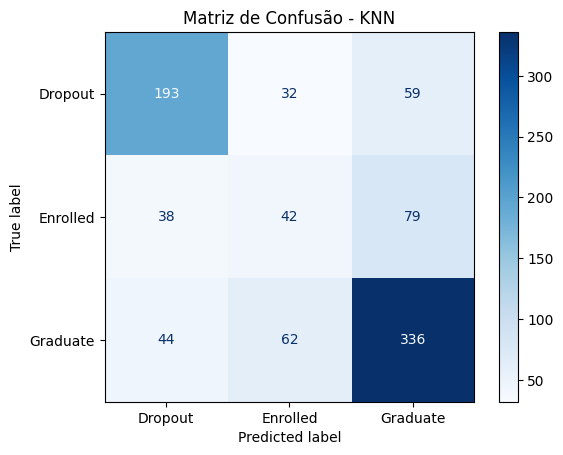

Naive Bayes: 

Acurácia: 0.6588
Precisão: 0.6334
Recall: 0.6588
F1-score: 0.6417
Matriz de Confusão:


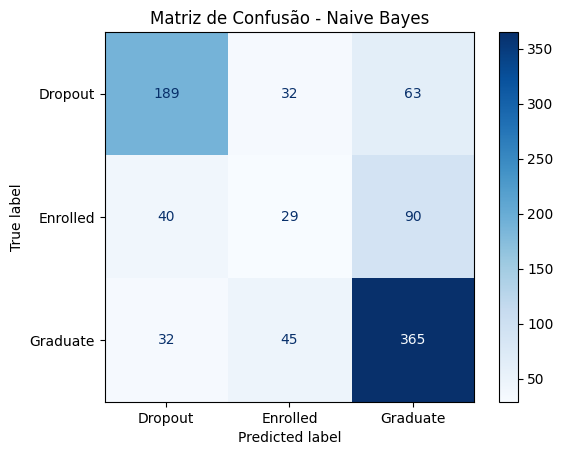

Árvore de Decisão: 

Acurácia: 0.7130
Precisão: 0.7037
Recall: 0.7130
F1-score: 0.7066
Matriz de Confusão:


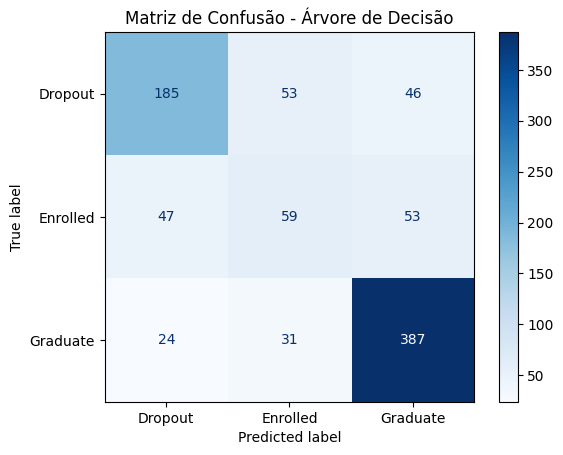

,Modelo,Acurácia,Precisão,Recall,F1-score
0,KNN,0.6452,0.6347,0.6452,0.6391
1,Naive Bayes,0.6588,0.6334,0.6588,0.6417
2,Árvore de Decisão,0.7130,0.7037,0.7130,0.7066


In [61]:
# Previsões dos modelos
y_pred_knn = pipeline_knn.predict(X_teste)
y_pred_nb = pipeline_nb.predict(X_teste)
y_pred_arvore = pipeline_arvore.predict(X_teste)


# Função para calcular as métricas
def avaliar_modelo(nome, y_teste, y_pred, modelo):
    print(f"{nome}: \n") 

    # Métricas
    acuracia = accuracy_score(y_teste, y_pred)
    precisao = precision_score(y_teste, y_pred, average='weighted')
    recall = recall_score(y_teste, y_pred, average='weighted')
    f1 = f1_score(y_teste, y_pred, average='weighted')

    print(f"Acurácia: {acuracia:.4f}")
    print(f"Precisão: {precisao:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")

    # Matriz de confusão
    print("Matriz de Confusão:")
    matriz = confusion_matrix(y_teste, y_pred, labels=modelo.classes_)

    disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=modelo.classes_)

    disp.plot(cmap=plt.cm.Blues)

    plt.title(f'Matriz de Confusão - {nome}')
    plt.show()

# Avaliação dos modelos
avaliar_modelo('KNN', y_teste, y_pred_knn, pipeline_knn.named_steps['classificador'])
avaliar_modelo('Naive Bayes', y_teste, y_pred_nb, pipeline_nb.named_steps['classificador'])
avaliar_modelo('Árvore de Decisão', y_teste, y_pred_arvore, pipeline_arvore.named_steps['classificador'])

#Comparação dos modelos
resultados = []

modelos = {
    'KNN': (pipeline_knn, y_pred_knn),
    'Naive Bayes': (pipeline_nb, y_pred_nb),
    'Árvore de Decisão': (pipeline_arvore, y_pred_arvore)
}

for nome, (modelo, y_pred) in modelos.items():
    resultados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_teste, y_pred),
        'Precisão': precision_score(y_teste, y_pred, average='weighted'),
        'Recall': recall_score(y_teste, y_pred, average='weighted'),
        'F1-score': f1_score(y_teste, y_pred, average='weighted')
    })

df_comparacao = pd.DataFrame(resultados)

display(df_comparacao.round(4))

## Comparação dos resultados

A tabela comparativa apresenta o desempenho dos três classificadores utilizando o mesmo conjunto de teste. Essa comparação permite observar qual modelo apresentou os melhores resultados nas métricas de avaliação.

De acordo com os resultados obtidos, a árvore de Decisão apresentou o melhor desempenho geral, destacando-se nas métricas de acurácia, precisão, recall e F1-score ponderado.

A acurácia indica o desempenho geral do modelo, mas não deve ser utilizada isoladamente. Como a base possui três classes com diferentes quantidades de registros, um classificador pode apresentar uma boa acurácia e, ainda assim, ter dificuldade para identificar corretamente uma das classes.

Por esse motivo, também foram analisadas a precisão, o recall, o F1-score e as matrizes de confusão, permitindo uma avaliação mais completa dos classificadores.

# Regressão


In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,  root_mean_squared_error, r2_score)

In [ ]:
# dataset estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition (obesidade para os mais próximos)
obesidade = fetch_ucirepo(id=544) 
df_obesidade = pd.concat([obesidade.data.features, obesidade.data.targets], axis=1)

linhas_obesidade = df_obesidade.shape[0]
colunas_obesidade = df_obesidade.shape[1]

#Weight: Peso (target)
classes_obesidade = df_obesidade['Weight'].unique()
contagem_classes_obesidade = df_obesidade['Weight'].value_counts()
qntd_classes_obesidade = len(classes_obesidade)
porcentagem_classes_obesidade = (contagem_classes_obesidade / linhas_obesidade) * 100

distribuicao_obesidade = pd.DataFrame({
    'Quantidade': contagem_classes_obesidade,
    'Porcentagem (%)': porcentagem_classes_obesidade.round(2)
})

print("Número de linhas:", linhas_obesidade)
print("Número de colunas:", colunas_obesidade)
print("Distribuição das classes:")
print(distribuicao_obesidade)

In [ ]:
#spoiler: nao tem valores nulos
valores_nulos_obesidade = df_obesidade.isnull().sum()
#print("Valores nulos por coluna:", valores_nulos_obesidade)

#A variável alvo é Weight kkk
x_obesidade = df_obesidade.drop(['Weight', 'NObeyesdad'], axis=1)
y_obesidade = df_obesidade['Weight']
print("Descrição:", y_obesidade.describe())

# Identificar colunas
numericas = x_obesidade.select_dtypes(include=['number']).columns
categoricas = x_obesidade.select_dtypes(include=['object', 'category', 'bool']).columns

pipeline_numerico = Pipeline([
    ('imputacao', SimpleImputer(strategy='median')),
    ('normalizacao', MinMaxScaler())
])

pipeline_categorico = Pipeline([
    ('imputacao', SimpleImputer(strategy='most_frequent')),
    ('codificacao', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer([
    ('numerico', pipeline_numerico, numericas),
    ('categorico', pipeline_categorico, categoricas)
])


In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    x_obesidade,
    y_obesidade,
    test_size=0.2,
    random_state=42
)

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

preprocessador_visualizacao = preprocessador.fit(X_treino)

X_treino_processado = preprocessador_visualizacao.transform(X_treino)
X_teste_processado = preprocessador_visualizacao.transform(X_teste)

print("Atributos originais:", X_treino.shape[1])
print("Atributos após processamento:", X_treino_processado.shape[1])

print("\nQuantidade de registros de treinamento:", X_treino.shape[0], "\n")
print("\nQuantidade de registros de teste:", X_teste.shape[0], "\n")

def criar_pipeline(modelo):
    return Pipeline([
        ('preprocessamento', preprocessador),
        ('classificador', modelo)
    ])
    
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Selecionar o melhor K
grid_knn = GridSearchCV(
    criar_pipeline(KNeighborsClassifier()),
    param_grid={
        'classificador__n_neighbors': [5, 10, 20]
    },
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_knn.fit(X_treino, y_treino)

# Selecionar a melhor profundidade
grid_arvore = GridSearchCV(
    criar_pipeline(DecisionTreeClassifier(random_state=42)),
    param_grid={
        'classificador__max_depth': [5, 10, 15]
    },
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_arvore.fit(X_treino, y_treino)

print("Melhor K:", grid_knn.best_params_)
print("Melhor profundidade:", grid_arvore.best_params_)

pipeline_knn = grid_knn.best_estimator_
pipeline_arvore = grid_arvore.best_estimator_

pipeline_nb = criar_pipeline(GaussianNB())
pipeline_nb.fit(X_treino, y_treino)